# 02 — L2: população, área e densidade de pronto-atendimentos

## Pergunta desta fase

**A densidade de pronto-atendimentos acompanha a densidade populacional como prevê a referência teórica para serviços públicos?**

Vamos construir os conceitos e os gráficos em ordem, antes de interpretar o expoente.

- **Principal:** estabelecimentos do tipo 73 do CNES que atendem o SUS.
- **Robustez:** todos os estabelecimentos do tipo 73 das capitais.
- **Entrada:** setores corrigidos em [01_correcao_setores.ipynb](01_correcao_setores.ipynb).
- **Ajuste autorizado:** OLS em log-log e intervalo percentil de 95% com **2.000 reamostragens bootstrap das áreas de atendimento**.
- **Unidades no mesmo nó:** compartilham uma área e a densidade conta todas as unidades do grupo.
- **Regra de acesso aprovada:** o setor é atribuído à unidade que minimiza ligação setor–rua + rota pela rede + ligação unidade–rua.
- **Exceção registrada:** unidade sem setor que passe pelos filtros não forma uma observação de área no L2. Ela continua no cadastro e nas contagens municipais; sua situação é mostrada à parte.

Não refazemos L1, a análise de renda ou L3 neste notebook. Elas terão notebooks próprios e discussão das escolhas que ainda faltarem.

## 1. População, área e duas densidades

Para uma área de atendimento $j$:

| Símbolo | O que significa | Unidade |
|---|---|---|
| $A_j$ | Soma das áreas oficiais dos setores válidos associados ao nó de atendimento | km² |
| $P_j$ | Soma da população desses setores | moradores |
| $m_j$ | Quantidade de estabelecimentos representados no nó | unidades |
| $\rho_j=P_j/A_j$ | Densidade populacional | moradores/km² |
| $D_j=m_j/A_j$ | Densidade de pronto-atendimentos | unidades/km² |

Quando $m=1$, recuperamos $D=1/A$ do plano original. Em Porto Alegre, o grupo de Bom Jesus tem $m=2$ na versão com todos, sem duplicar sua população ou sua área. Segundo o cadastro, apenas uma dessas duas unidades entra na versão SUS.

Uma área de atendimento aqui é **estimada pela proximidade na rede**, não uma divisão oficial do SUS. Ela usa os setores com moradores e ligação à rua de até 2 km, conforme o filtro do projeto.


**Execução atual:** as distâncias vêm do recálculo completo em `notebooks/retomada/03_distancias_completas.ipynb`, com a menor distância total aprovada pela autora. Em Todos, o PA Ilha de Maré permanece no cadastro, mas não forma uma área no L2 porque seus setores não passam pelo filtro de ligação à rua.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from scipy import stats

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLANO.md").exists())
PROC = RAIZ / "dados" / "processados"
RETOMADA = PROC / "retomada"
DIST = RETOMADA / "distancias"
SAIDA = PROC / "analises" / "L2"
FIG = RAIZ / "figuras" / "L2"
SAIDA.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo  # Apenas apresentação.
estilo.aplicar()
N_BOOT = 2000
SEMENTE = 42  # Mesma semente adotada na exploração anterior.

grupos = pd.read_csv(RETOMADA / "grupos_unidades.csv",
                     dtype={"CO_CNES_representante": str, "codigos_unidades": str})
cadastro_capitais = pd.read_csv(PROC / "capitais_resumo.csv")
def slug(nome):
    import unicodedata
    return unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode().split(" - ")[0].lower().replace(" ", "_")
nome_capital = dict(zip(cadastro_capitais.municipio.map(slug), cadastro_capitais.municipio))

def salvar_figura(figura, nome):
    figura.savefig(FIG / f"{nome}.png")
    figura.savefig(FIG / f"{nome}.pdf")

print("Bootstrap:", N_BOOT, "reamostragens por versão; semente:", SEMENTE)
print("Dados:", DIST.relative_to(RAIZ))


Bootstrap: 2000 reamostragens por versão; semente: 42
Dados: dados/processados/retomada/distancias


## 2. Ler os setores corrigidos e aplicar o filtro combinado

Mantemos setores com:

- população positiva;
- ligação ao nó da rua de até **2.000 m**;
- distância finita até o atendimento.

Não excluímos um setor da L2 porque sua renda está ausente: a renda não entra neste ajuste. Para a futura análise de renda, guardamos a média ponderada pela população com renda disponível e sua cobertura.

Se houver código de setor repetido, área não positiva ou grupo desconhecido, a execução para em vez de ajustar silenciosamente dados inconsistentes.


In [2]:
setores = {}
filtros = []
for versao, sufixo in [("SUS", "drive_sus"), ("Todos", "drive")]:
    arquivos = sorted(DIST.glob(f"*_{sufixo}_setores.csv"))
    assert len(arquivos) == 26, f"Esperados 26 arquivos: {versao}"
    partes = []
    for arquivo in arquivos:
        tabela = pd.read_csv(arquivo, dtype={"CD_SETOR": str, "CO_CNES": str})
        tabela["capital"] = nome_capital[arquivo.name.removesuffix(f"_{sufixo}_setores.csv")]
        partes.append(tabela)
    bruto = pd.concat(partes, ignore_index=True)
    assert not bruto.CD_SETOR.duplicated().any()
    mascara = (bruto.populacao > 0) & (bruto.ligacao_m <= 2000) & np.isfinite(bruto.d_m)
    valido = bruto.loc[mascara].copy()
    assert (valido.AREA_KM2 > 0).all() and np.isfinite(valido.AREA_KM2).all()
    setores[versao] = valido
    filtros.append({
        "versao": versao, "setores_no_arquivo": len(bruto), "setores_validos": len(valido),
        "populacao_habitada_antes_filtro": bruto.loc[bruto.populacao > 0].populacao.sum(),
        "populacao_valida": valido.populacao.sum(),
        "populacao_excluida": bruto.loc[bruto.populacao > 0].populacao.sum() - valido.populacao.sum(),
        "setores_validos_sem_renda": int(valido.renda_media.isna().sum()),
    })
display(pd.DataFrame(filtros).set_index("versao"))


,setores_no_arquivo,setores_validos,populacao_habitada_antes_filtro,populacao_valida,populacao_excluida,setores_validos_sem_renda
versao,,,,,,
SUS,92782,90985,45883071,45770048,113023,813
Todos,92782,90985,45883071,45770048,113023,813


## 3. Formar as áreas de atendimento

Somamos área e população dos setores associados ao mesmo atendimento, identificado pelo CNES vencedor na menor distância total. Depois incorporamos a contagem de unidades do grupo. Se nenhum setor de um grupo passar pelos filtros, ele não tem área ou densidade calculável para a regressão e fica registrado à parte.

**Não duplicamos as linhas dos setores para representar duas unidades.** O fator $m$ entra apenas no cálculo da densidade de estabelecimentos. A reamostragem também tratará a área compartilhada como uma observação.

A renda é calculada como previsto no planejamento: média das rendas médias dos setores, ponderada por sua população com renda disponível. A coluna de cobertura indica a fração da população incluída nessa média; a renda não é usada para selecionar os pontos da L2.


In [3]:
areas = {}
grupos_sem_area = []
contagem_sem_area = {}
for versao, tabela in setores.items():
    tabela = tabela.copy()
    com_renda = tabela.renda_media.notna() & np.isfinite(tabela.renda_media)
    tabela["pop_com_renda"] = tabela.populacao.where(com_renda, 0)
    tabela["pop_vezes_renda"] = (tabela.populacao * tabela.renda_media).where(com_renda, 0)
    agregadas = tabela.groupby(["capital", "CO_CNES"], as_index=False).agg(
        area_km2=("AREA_KM2", "sum"), populacao=("populacao", "sum"),
        n_setores=("CD_SETOR", "size"), pop_com_renda=("pop_com_renda", "sum"),
        soma_pop_renda=("pop_vezes_renda", "sum")
    )
    cadastro = grupos.loc[grupos.versao == versao].rename(columns={"CO_CNES_representante": "CO_CNES"})
    ausentes = cadastro.merge(agregadas[["capital", "CO_CNES"]], on=["capital", "CO_CNES"],
                             how="left", indicator=True)
    ausentes = ausentes.loc[ausentes["_merge"] == "left_only"].copy()
    contagem_sem_area[versao] = ausentes
    if not ausentes.empty:
        ausentes["versao"] = versao
        grupos_sem_area.append(ausentes)
        display(Markdown(
            f"**Registro metodológico — {versao}:** {len(ausentes)} grupo(s) não tem(têm) "
            "setor que passe pelos filtros; por isso não forma(m) área para o L2. "
            "A unidade continua no cadastro municipal e a exceção fica documentada."
        ))
        display(ausentes[["capital", "CO_CNES", "n_unidades", "codigos_unidades", "nomes_unidades"]])
    agregadas = agregadas.merge(
        cadastro[["capital", "CO_CNES", "n_unidades", "codigos_unidades", "nomes_unidades"]],
        on=["capital", "CO_CNES"], how="left", validate="one_to_one"
    )
    assert agregadas.n_unidades.notna().all()
    agregadas["renda_media"] = (
        agregadas.soma_pop_renda / agregadas.pop_com_renda.where(agregadas.pop_com_renda > 0)
    )
    agregadas["cobertura_renda"] = agregadas.pop_com_renda / agregadas.populacao
    agregadas["D"] = agregadas.n_unidades / agregadas.area_km2
    agregadas["rho"] = agregadas.populacao / agregadas.area_km2
    agregadas["log10_D"] = np.log10(agregadas.D)
    agregadas["log10_rho"] = np.log10(agregadas.rho)
    agregadas["versao"] = versao
    assert np.isfinite(agregadas[["log10_D", "log10_rho"]]).all().all()
    np.testing.assert_allclose(agregadas.populacao.sum(), tabela.populacao.sum())
    np.testing.assert_allclose(agregadas.area_km2.sum(), tabela.AREA_KM2.sum())
    np.testing.assert_allclose(
        agregadas.n_unidades.sum() + ausentes.n_unidades.sum(), cadastro.n_unidades.sum()
    )
    areas[versao] = agregadas.sort_values(["capital", "CO_CNES"]).reset_index(drop=True)
    agregadas.to_csv(SAIDA / f"areas_{versao.lower()}.csv", index=False)

if grupos_sem_area:
    grupos_sem_area = pd.concat(grupos_sem_area, ignore_index=True)
else:
    grupos_sem_area = pd.DataFrame()
grupos_sem_area.to_csv(RETOMADA / "grupos_sem_area_L2.csv", index=False)

resumo_areas = pd.DataFrame([{
    "versao": versao, "capitais": dados.capital.nunique(), "areas": len(dados),
    "estabelecimentos_representados": dados.n_unidades.sum(),
    "grupos_sem_area_valida": len(contagem_sem_area[versao]),
    "unidades_sem_area_valida": contagem_sem_area[versao].n_unidades.sum(),
    "populacao": dados.populacao.sum(), "area_km2": dados.area_km2.sum(),
    "renda_disponivel_em_areas": dados.renda_media.notna().sum()
} for versao, dados in areas.items()])
display(resumo_areas.set_index("versao"))
display(areas["Todos"].loc[areas["Todos"].n_unidades > 1, [
    "capital", "codigos_unidades", "n_unidades", "area_km2", "populacao", "rho", "D"
]])


**Registro metodológico — Todos:** 1 grupo(s) não tem(têm) setor que passe pelos filtros; por isso não forma(m) área para o L2. A unidade continua no cadastro municipal e a exceção fica documentada.

,capital,CO_CNES,n_unidades,codigos_unidades,nomes_unidades
149,Salvador - BA,4445252,1,4445252,PA ILHA DE MARE


,capitais,areas,estabelecimentos_representados,grupos_sem_area_valida,unidades_sem_area_valida,populacao,area_km2,renda_disponivel_em_areas
versao,,,,,,,,
SUS,26,245,245,0,0,45770048,33994.585274,245
Todos,26,272,273,1,1,45770048,33994.585274,272


,capital,codigos_unidades,n_unidades,area_km2,populacao,rho,D
114,Porto Alegre - RS,4758749;6537650,2,47.553416,240250,5052.213325,0.042058


## 4. Antes da regressão: como variam área e densidade?

Os histogramas mostram a versão principal, **SUS**. Cada observação é uma área de atendimento, independentemente de sua população. Isso corresponde à unidade de análise e ao peso igual de cada área no ajuste aprovado.

Os eixos horizontais usam escala logarítmica: a mesma distância no eixo representa o mesmo fator de multiplicação. Por exemplo, ir de 1 para 10 tem o mesmo espaço que ir de 10 para 100. As alturas mostram contagem de áreas, não probabilidade por unidade de densidade.


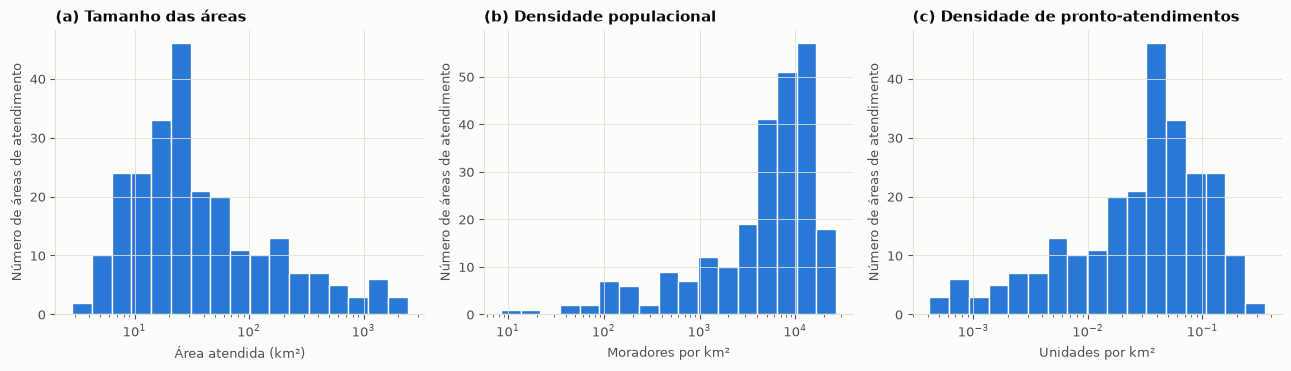

,area_km2,populacao,rho,D
count,245.000,245.000,245.000,245.000
mean,138.753,186816.522,7367.197,0.051
std,339.024,104597.106,5461.448,0.052
min,2.851,10630.000,8.381,0.000
25%,14.608,110321.000,2867.638,0.013
50%,27.208,172707.000,6845.021,0.037
75%,74.864,239504.000,11142.306,0.068
max,2414.694,695976.000,26672.184,0.351


In [4]:
principal = areas["SUS"]
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
variaveis = [
    ("area_km2", "Área atendida (km²)", "(a) Tamanho das áreas"),
    ("rho", "Moradores por km²", "(b) Densidade populacional"),
    ("D", "Unidades por km²", "(c) Densidade de pronto-atendimentos"),
]
for ax, (coluna, rotulo, titulo) in zip(eixos, variaveis):
    valores = principal[coluna]
    limites = np.logspace(np.log10(valores.min()), np.log10(valores.max()), 18)
    ax.hist(valores, bins=limites, color=estilo.AZUL, edgecolor=estilo.SUPERFICIE)
    ax.set_xscale("log")
    ax.set_xlabel(rotulo)
    ax.set_ylabel("Número de áreas de atendimento")
    ax.set_title(titulo)
fig.tight_layout()
salvar_figura(fig, "01_distribuicoes")
plt.show()

display(principal[["area_km2", "populacao", "rho", "D"]].describe(
    percentiles=[0.25, 0.5, 0.75]
).round(3))


### População e área não são a mesma coisa

Uma área territorial maior pode reunir mais moradores, mas também pode ser pouco densa. No gráfico abaixo, uma reta de densidade constante segue $P=\rho A$.

As linhas cinzas ilustram **1.000 e 10.000 moradores/km²**. São referências de leitura, não cortes usados para classificar, selecionar ou excluir os dados.

Cada ponto continua sendo uma área estimada de atendimento. Valores extremos são mostrados, sem exclusões adicionais.


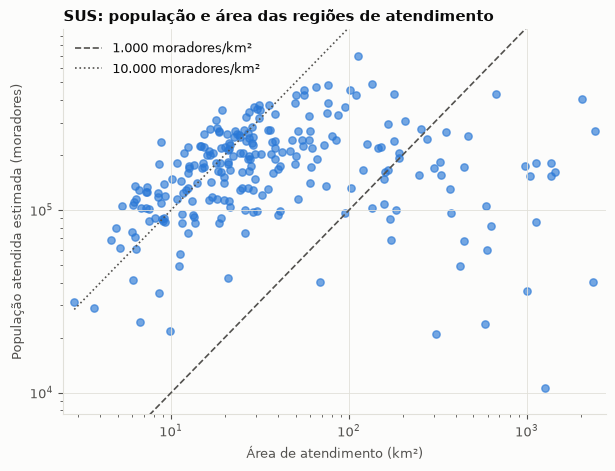

,capital,codigos_unidades,area_km2,populacao,rho,D
115,Porto Velho - RO,9743081,1268.390,10630,8.381,0.001
35,Campo Grande - MS,7924798,2343.452,40140,17.129,0.000
114,Porto Velho - RO,8291462,1003.182,36089,35.975,0.001
149,Rio de Janeiro - RJ,6858317,8.809,234956,26672.184,0.114
219,São Paulo - SP,6218830,6.283,134563,21418.355,0.159
197,São Paulo - SP,4049918,8.509,179547,21101.811,0.118


In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(principal.area_km2, principal.populacao, color=estilo.AZUL, alpha=0.65, s=28)
eixo_area = np.logspace(np.log10(principal.area_km2.min()), np.log10(principal.area_km2.max()), 200)
for densidade, linha in [(1000, "--"), (10000, ":")]:
    ax.plot(eixo_area, densidade * eixo_area, linha, color=estilo.TEXTO_2,
            linewidth=1.2, label=f"{densidade:,.0f} moradores/km²".replace(",", "."))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(principal.area_km2.min()/1.15, principal.area_km2.max()*1.15)
ax.set_ylim(principal.populacao.min()/1.4, principal.populacao.max()*1.4)
ax.set_xlabel("Área de atendimento (km²)")
ax.set_ylabel("População atendida estimada (moradores)")
ax.set_title("SUS: população e área das regiões de atendimento")
ax.legend()
salvar_figura(fig, "02_populacao_area")
plt.show()

extremos = pd.concat([principal.nsmallest(3, "rho"), principal.nlargest(3, "rho")])
display(extremos[["capital", "codigos_unidades", "area_km2", "populacao", "rho", "D"]].round(3))


## 5. A lei de densidade e seu expoente

A relação prevista é

$$D = C\rho^\alpha.$$

Aplicando logaritmo decimal:

$$\log_{10}D = c + \alpha\log_{10}\rho, \qquad c=\log_{10}C.$$

A reta ajustada minimiza a soma dos quadrados dos desvios **em logaritmo**, com o mesmo peso para cada área. Isso estima uma relação média entre as áreas; não é um ajuste da distribuição de frequências de uma variável.

**Como ler α:** se a densidade populacional multiplicar por 2, a densidade prevista de pronto-atendimentos multiplica por $2^\alpha$.

- $\alpha=2/3$: referência teórica para a distribuição que minimiza distância média sob as hipóteses do modelo de Gastner e Newman; não é uma certificação de eficiência.
- $\alpha=1$: densidade de unidades proporcional à densidade de moradores; implica uma razão unidades/moradores constante no modelo. A bibliografia a discute também no contexto de serviços comerciais, mas um expoente próximo de 1 não prova motivação comercial.

As referências serão comparadas com o intervalo de incerteza, não apenas com a estimativa pontual.


In [6]:
def ajustar_com_bootstrap(tabela):
    x = tabela.log10_rho.to_numpy()
    y = tabela.log10_D.to_numpy()
    ajuste = stats.linregress(x, y)
    rng = np.random.default_rng(SEMENTE)
    coeficientes = []
    for _ in range(N_BOOT):
        indices = rng.integers(0, len(x), len(x))
        if np.ptp(x[indices]) > 0:
            alpha, c = np.polyfit(x[indices], y[indices], 1)
            coeficientes.append((alpha, c))
    boot = pd.DataFrame(coeficientes, columns=["alpha", "c"])
    assert len(boot) == N_BOOT, "Reamostragem degenerada: investigar."
    inferior, superior = np.percentile(boot.alpha, [2.5, 97.5])
    resultado = {
        "versao": tabela.versao.iloc[0],
        "n_areas": len(tabela), "n_estabelecimentos": int(tabela.n_unidades.sum()),
        "n_capitais": tabela.capital.nunique(),
        "alpha": ajuste.slope, "c": ajuste.intercept,
        "ic95_inferior": inferior, "ic95_superior": superior,
        "R2_loglog": ajuste.rvalue**2, "n_bootstrap": len(boot), "semente": SEMENTE,
        "fator_D_ao_dobrar_rho": 2**ajuste.slope
    }
    return resultado, boot

ajustes, bootstraps = {}, {}
for versao, tabela in areas.items():
    ajustes[versao], bootstraps[versao] = ajustar_com_bootstrap(tabela)
    tabela["log10_D_ajustado"] = ajustes[versao]["c"] + ajustes[versao]["alpha"] * tabela.log10_rho
    tabela["residuo_L2"] = tabela.log10_D - tabela.log10_D_ajustado
    tabela.to_csv(SAIDA / f"areas_{versao.lower()}.csv", index=False)
    bootstraps[versao].to_csv(SAIDA / f"bootstrap_{versao.lower()}.csv", index=False)
resultados = pd.DataFrame(ajustes.values())
resultados.to_csv(SAIDA / "resultados_L2.csv", index=False)
display(resultados.set_index("versao").round(4))


,n_areas,n_estabelecimentos,n_capitais,alpha,c,ic95_inferior,ic95_superior,R2_loglog,n_bootstrap,semente,fator_D_ao_dobrar_rho
versao,,,,,,,,,,,
SUS,245,245,26,0.8615,-4.6953,0.7968,0.9348,0.8154,2000,42,1.8169
Todos,272,273,26,0.8991,-4.7794,0.8337,0.9727,0.8093,2000,42,1.8648


## 6. O que significa o intervalo bootstrap?

Sorteamos áreas de atendimento **com reposição**, com o mesmo número de áreas da amostra original, e repetimos o ajuste 2.000 vezes. Os percentis 2,5 e 97,5 dos expoentes formam o intervalo de 95%.

Um valor de referência dentro do intervalo é **compatível com este ajuste e seu procedimento de incerteza**; isso não prova que o valor verdadeiro seja exatamente aquele. Um valor fora do intervalo indica diferença segundo este procedimento e suas hipóteses.

O procedimento não representa explicitamente a dependência espacial nem a dependência entre áreas da mesma capital. Os intervalos são condicionais a essa escolha já aprovada.

Nos gráficos seguintes, as linhas de referência passam pela média dos logaritmos dos dados. Comparar suas inclinações ajuda a ler o expoente; suas alturas não foram tratadas como previsões independentes.


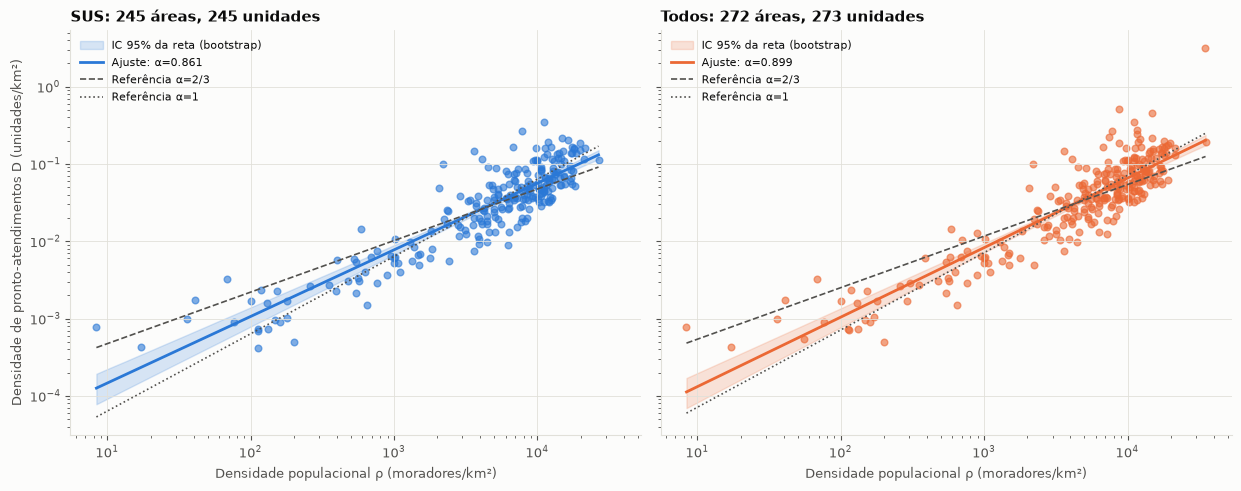

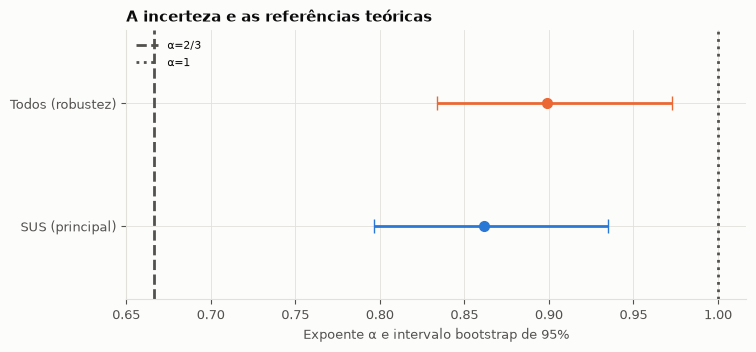

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(12.5, 5), sharex=True, sharey=True)
for ax, versao, cor in zip(eixos, ["SUS", "Todos"], [estilo.AZUL, estilo.LARANJA]):
    tabela, ajuste, boot = areas[versao], ajustes[versao], bootstraps[versao]
    xs_log = np.linspace(tabela.log10_rho.min(), tabela.log10_rho.max(), 200)
    xs = 10**xs_log
    previsoes_boot = boot.c.to_numpy()[:, None] + boot.alpha.to_numpy()[:, None] * xs_log
    baixo, alto = 10**np.percentile(previsoes_boot, [2.5, 97.5], axis=0)
    ax.scatter(tabela.rho, tabela.D, color=cor, alpha=0.6, s=23)
    ax.fill_between(xs, baixo, alto, color=cor, alpha=0.18, label="IC 95% da reta (bootstrap)")
    ax.plot(xs, 10**(ajuste["c"] + ajuste["alpha"]*xs_log), color=cor, label=f'Ajuste: α={ajuste["alpha"]:.3f}')
    x_centro, y_centro = tabela.log10_rho.mean(), tabela.log10_D.mean()
    for referencia, linha, rotulo in [(2/3, "--", "Referência α=2/3"), (1, ":", "Referência α=1")]:
        ax.plot(xs, 10**(y_centro + referencia*(xs_log-x_centro)),
                linha, color=estilo.TEXTO_2, linewidth=1.2, label=rotulo)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Densidade populacional ρ (moradores/km²)")
    ax.set_title(f'{versao}: {len(tabela)} áreas, {int(tabela.n_unidades.sum())} unidades')
    ax.legend(fontsize=8, loc="upper left")
eixos[0].set_ylabel("Densidade de pronto-atendimentos D (unidades/km²)")
fig.tight_layout()
salvar_figura(fig, "03_lei_densidade")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
for i, (versao, cor) in enumerate([("SUS", estilo.AZUL), ("Todos", estilo.LARANJA)]):
    ajuste = ajustes[versao]
    erro = np.array([[ajuste["alpha"]-ajuste["ic95_inferior"]],
                     [ajuste["ic95_superior"]-ajuste["alpha"]]])
    ax.errorbar(ajuste["alpha"], i, xerr=erro, fmt="o", color=cor, capsize=5, markersize=7)
ax.axvline(2/3, color=estilo.TEXTO_2, linestyle="--", label="α=2/3")
ax.axvline(1, color=estilo.TEXTO_2, linestyle=":", label="α=1")
ax.set_yticks([0, 1], ["SUS (principal)", "Todos (robustez)"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Expoente α e intervalo bootstrap de 95%")
ax.set_title("A incerteza e as referências teóricas")
ax.legend(loc="upper left", fontsize=8)
salvar_figura(fig, "04_intervalos_alpha")
plt.show()


## 7. Interpretar o resultado em palavras

O texto abaixo é gerado a partir das estimativas, sem fixar de antemão uma conclusão. A comparação das duas versões é um teste de sensibilidade à inclusão de unidades que não atendem o SUS segundo o cadastro.

Não usamos a sobreposição dos dois intervalos como teste formal de igualdade entre os expoentes.


In [8]:
def posicao_referencia(ajuste, referencia):
    if ajuste["ic95_inferior"] <= referencia <= ajuste["ic95_superior"]:
        return "está dentro do intervalo"
    if referencia < ajuste["ic95_inferior"]:
        return "está abaixo do intervalo"
    return "está acima do intervalo"

paragrafos = []
for versao in ["SUS", "Todos"]:
    a = ajustes[versao]
    texto = (
        f'**{versao}:** α = **{a["alpha"]:.3f}**, IC 95% '
        f'**[{a["ic95_inferior"]:.3f}; {a["ic95_superior"]:.3f}]**, '
        f'com {a["n_areas"]} áreas de atendimento em {a["n_capitais"]} capitais. '
        f'A referência **2/3 {posicao_referencia(a, 2/3)}**; '
        f'a referência **1 {posicao_referencia(a, 1)}**. '
        f'No ajuste, dobrar a densidade populacional está associado a multiplicar '
        f'a densidade de pronto-atendimentos por **{a["fator_D_ao_dobrar_rho"]:.2f}**. '
        f'O R² em log-log é {a["R2_loglog"]:.3f}.'
    )
    paragrafos.append(texto)
a_principal = ajustes["SUS"]
paragrafos.append(
    f'**Comparação para explicar ao professor:** quando ρ dobra, '
    f'a referência α=2/3 corresponde a multiplicar D por {2**(2/3):.2f}; '
    f'o ajuste SUS corresponde a {a_principal["fator_D_ao_dobrar_rho"]:.2f}; '
    f'e a proporcionalidade α=1 corresponde a 2,00. '
    'Esses fatores descrevem as retas comparadas, não uma mudança real '
    'na quantidade de unidades de uma cidade ao longo do tempo. '
    'O ajuste reúne áreas de atendimento de capitais diferentes e '
    'não comprova que a localização seja ótima nem responde ainda sobre renda.'
)
display(Markdown("\n\n".join(paragrafos)))
texto_resultados = "\n\n".join(paragrafos)
(SAIDA / "interpretacao_L2.md").write_text(texto_resultados + "\n", encoding="utf-8")


**SUS:** α = **0.861**, IC 95% **[0.797; 0.935]**, com 245 áreas de atendimento em 26 capitais. A referência **2/3 está abaixo do intervalo**; a referência **1 está acima do intervalo**. No ajuste, dobrar a densidade populacional está associado a multiplicar a densidade de pronto-atendimentos por **1.82**. O R² em log-log é 0.815.

**Todos:** α = **0.899**, IC 95% **[0.834; 0.973]**, com 272 áreas de atendimento em 26 capitais. A referência **2/3 está abaixo do intervalo**; a referência **1 está acima do intervalo**. No ajuste, dobrar a densidade populacional está associado a multiplicar a densidade de pronto-atendimentos por **1.86**. O R² em log-log é 0.809.

**Comparação para explicar ao professor:** quando ρ dobra, a referência α=2/3 corresponde a multiplicar D por 1.59; o ajuste SUS corresponde a 1.82; e a proporcionalidade α=1 corresponde a 2,00. Esses fatores descrevem as retas comparadas, não uma mudança real na quantidade de unidades de uma cidade ao longo do tempo. O ajuste reúne áreas de atendimento de capitais diferentes e não comprova que a localização seja ótima nem responde ainda sobre renda.

1125

## 8. O que podemos e o que ainda não podemos concluir?

- O expoente descreve a associação **entre as áreas de atendimento reunidas das capitais**. Não é necessariamente a relação dentro de cada capital.
- $D$ e $\rho$ compartilham a área no denominador, gerando correlação matemática. Gastner e Newman discutem esse problema e os limites do ajuste log-log; um R² alto não resolve essa questão.
- Comparar com $2/3$ é usar uma referência teórica sob hipóteses. Não medimos aqui quanto a localização real está distante da melhor distribuição possível.
- A rede para carro, seus sentidos, o recorte municipal e o uso de um ponto por setor limitam a aproximação. Distância não é tempo.
- Todos os estabelecimentos contam como uma unidade, independentemente de capacidade, especialidade ou demanda. No grupo compartilhado, $m=2$ conta estabelecimentos, não confirma o dobro de capacidade.
- Os intervalos bootstrap de áreas não incorporam explicitamente a dependência entre áreas da mesma cidade.
- O resultado **não responde ainda se a oferta favorece ricos ou pobres**. A próxima fase discutirá a renda, a densidade e as diferenças entre capitais.

### Material teórico utilizado

- [Planejamento](../planejamento.md), seção 6.2, e [PLANO.md](../PLANO.md), seção 7.1, com a adaptação $D=m/A$ aprovada pela autora.
- Gastner e Newman (2006), *Optimal design of spatial distribution networks*, seção II, p. 016117-2: relação $D\propto\rho^{2/3}$ e discussão dos denominadores compartilhados.
- Xu et al. (2020), *Deconstructing laws of accessibility and facility distribution in cities*, pp. 4–5: densidades em áreas de atendimento e limites da lei de dois terços na escala intraurbana.
- Aula 4, slide 44: referência de Um et al. para serviços públicos e comerciais.

Os artigos estão em `Bibliografia/`. Não foram acrescentadas referências externas.

### Arquivos gerados

- `dados/processados/analises/L2/areas_sus.csv` e `areas_todos.csv`: áreas, população, número de unidades, densidades, renda agregada e resíduos da L2.
- `resultados_L2.csv`: estimativas, intervalos, tamanhos amostrais, R² e configuração do bootstrap.
- `bootstrap_sus.csv` e `bootstrap_todos.csv`: os 2.000 pares de coeficientes de cada versão.
- `interpretacao_L2.md`: interpretação numérica reproduzível.
- `figuras/L2/`: gráficos deste notebook, em PNG e PDF.

**Continuação:** após a discussão, a autora escolheu o modelo conjunto simples, sem efeitos fixos por capital, para manter o escopo de três páginas. A análise está em [03_renda_residuos.ipynb](03_renda_residuos.ipynb), com as diferenças entre capitais explicitadas como limitação.
